

* This Notebook Trains 5 Neural Networks on the entire Centralized data  
* The best model will be then used as a Global Model for Federated Learning





Imports

In [8]:
import os
from pathlib import Path
import random
import copy
import time

import numpy as np
import pandas as pd

from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms, models


from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

Mount Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Check GPU availability

In [2]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


Defining Configurations for the Notebook

In [4]:
CONFIG = {

    "image_size":224,

    "batch_size":32,

    "epochs":30,

    "lr":1e-4,

    "num_classes":4,

    "patience":5,

    "seed":42

}

Defining a Random Seed for Reproducible Experiments

In [5]:
def seed_everything(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG["seed"])

Paths

In [34]:
BASE_DIR = Path("/content/drive/MyDrive/fyp")

DATA_DIR = BASE_DIR/'Processed Dataset/images'

CSV_PATH = BASE_DIR/'Processed Dataset/metadata.csv'


MODEL_DIR = BASE_DIR/"models"

RESULT_DIR =BASE_DIR/'results'


os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

In [35]:
# Copy images to Colab local storage to speed up loading and training
import os
import shutil

LOCAL_DATA_DIR = "/content/images"
SRC_DATA_DIR = BASE_DIR/'Processed Dataset/images'
print(f"Copying images from {SRC_DATA_DIR} to {LOCAL_DATA_DIR}...")

# Run rsync silently without showing progress for every file
!rsync -ah "{SRC_DATA_DIR}/" "{LOCAL_DATA_DIR}/"

# Update DATA_DIR to use the local fast storage path
DATA_DIR = Path(LOCAL_DATA_DIR)
print("Local image directory copying is complete!")
print("Local image directory is ready at:", DATA_DIR)
print("Number of images in local directory:", len(os.listdir(DATA_DIR)))

Copying images from /content/drive/MyDrive/fyp/Processed Dataset/images to /content/images...
Local image directory copying is complete!
Local image directory is ready at: /content/images
Number of images in local directory: 4479


Loading MetaData CSV for Images

In [11]:
df = pd.read_csv(CSV_PATH)


print(df.shape)

df.head()

(4478, 7)


,image,mask,class,label,patient_id,source,client_id
0,cheng_000000.png,cheng_000000_mask.png,meningioma,1,100360,cheng,NaN
1,cheng_000001.png,cheng_000001_mask.png,meningioma,1,101016,cheng,NaN
2,cheng_000002.png,cheng_000002_mask.png,meningioma,1,107494,cheng,NaN
3,cheng_000003.png,cheng_000003_mask.png,pituitary,3,112649,cheng,NaN
4,cheng_000004.png,cheng_000004_mask.png,pituitary,3,112649,cheng,NaN


In [12]:
df.label.value_counts()

,count
label,
2,1426
0,1414
3,930
1,708


Verifying Image in csv points to correct path before Training

In [13]:
sample = df.iloc[0]["image"]


sample_path = os.path.join(
    DATA_DIR,
    sample
)


print(sample_path)

print(
    "Exists:",
    os.path.exists(sample_path)
)

/content/drive/MyDrive/fyp/Processed Dataset/images/cheng_000000.png
Exists: True


Performing Train-val-test spit



*   We have to split on patient id
*   we have to handle missing patient ids for Non-tumor class just like we did while client simulation



In [15]:
# Create synthetic patient IDs for missing values

missing_patient = df["patient_id"].isna()


df.loc[
    missing_patient,
    "patient_id"
] = [
    f"NT_{i}"
    for i in range(
        1,
        missing_patient.sum()+1
    )
]


print(
    df["patient_id"].isna().sum()
)



0


In [21]:
df['patient_id'][df['source']=='kaggle'].iloc[:10]

,patient_id
3064,NT_1
3065,NT_2
3066,NT_3
3067,NT_4
3068,NT_5
3069,NT_6
3070,NT_7
3071,NT_8
3072,NT_9
3073,NT_10


Performing split to avoid data leakage

In [24]:
groups = df["patient_id"]


splitter = GroupShuffleSplit(
    test_size=0.2,
    random_state=42
)


train_idx, temp_idx = next(
    splitter.split(
        df,
        groups=groups
    )
)


train_df = df.iloc[train_idx]


temp_df = df.iloc[temp_idx]



splitter2 = GroupShuffleSplit(
    test_size=0.5,
    random_state=42
)


val_idx, test_idx = next(
    splitter2.split(
        temp_df,
        groups=temp_df["patient_id"]
    )
)


val_df = temp_df.iloc[val_idx]

test_df = temp_df.iloc[test_idx]



print(

    f'Train Images Size:{len(train_df)}\n',
    f'Validation Images Size :{len(val_df)}\n',
    f'Tess images size:{len(test_df)}\n'
)

Train Images Size:3525
 Validation Images Size :501
 Tess images size:452



Saving my splits

In [27]:
train_df.to_csv(
    RESULT_DIR/"train.csv",
    index=False
)

val_df.to_csv(
    RESULT_DIR/"val.csv",
    index=False
)

test_df.to_csv(
    RESULT_DIR/"test.csv",
    index=False
)

Defining Preprocessing For Train and Test data

In [30]:
train_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.RandomRotation(10),

    transforms.RandomHorizontalFlip(),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )

])


val_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )

])

Defining a Dataset Class

In [32]:
class BrainTumorDataset(Dataset):

    def __init__(self,dataframe,image_dir,transform=None):

        self.df = dataframe.reset_index(drop=True)

        self.image_dir=image_dir

        self.transform=transform


    def __len__(self):

        return len(self.df)


    def __getitem__(self,index):

        row=self.df.iloc[index]


        path=os.path.join(
            self.image_dir,
            row["image"]
        )


        image=Image.open(path).convert("RGB")


        label=int(row["label"])


        if self.transform:

            image=self.transform(image)


        return image,label

Making DataLoaders for all Splits

In [36]:
train_dataset = BrainTumorDataset(
    train_df,
    DATA_DIR,
    train_transform
)


val_dataset = BrainTumorDataset(
    val_df,
    DATA_DIR,
    val_transform
)


test_dataset = BrainTumorDataset(
    test_df,
    DATA_DIR,
    val_transform
)





In [39]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)


val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)


test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

#Model Training

#Custom CNN

In [40]:
class CustomCNN(nn.Module):

    def __init__(self, num_classes=4):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3,32,3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),


            nn.Conv2d(32,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),


            nn.Conv2d(64,128,3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)

        )


        self.classifier = nn.Sequential(

            nn.AdaptiveAvgPool2d((1,1)),

            nn.Flatten(),

            nn.Linear(128,num_classes)

        )


    def forward(self,x):

        x=self.features(x)

        x=self.classifier(x)

        return x

Creating a Model Factory for Custom CNN and Pre-Trained Models

In [41]:
def get_model(name, num_classes=4):

    if name=="cnn":

        model=CustomCNN(num_classes)


    elif name=="resnet50":

        model=models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes
        )


    elif name=="densenet121":

        model=models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )

        model.classifier=nn.Linear(
            model.classifier.in_features,
            num_classes
        )


    elif name=="efficientnet_b0":

        model=models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        model.classifier[1]=nn.Linear(
            model.classifier[1].in_features,
            num_classes
        )


    elif name=="mobilenet_v3":

        model=models.mobilenet_v3_large(
            weights=models.MobileNet_V3_Large_Weights.DEFAULT
        )

        model.classifier[3]=nn.Linear(
            model.classifier[3].in_features,
            num_classes
        )


    else:

        raise ValueError(
            "Unknown model"
        )


    return model.to(DEVICE)

Test Model Factory

In [42]:
model_names = [
    "cnn",
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "mobilenet_v3"
]


for name in model_names:

    model=get_model(name)

    print(
        name,
        "loaded successfully"
    )

cnn loaded successfully
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 146MB/s]


resnet50 loaded successfully
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 153MB/s]


densenet121 loaded successfully
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 181MB/s]


efficientnet_b0 loaded successfully
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 156MB/s]


mobilenet_v3 loaded successfully


Getting Class Weights for our Loss function

In [45]:
from sklearn.utils.class_weight import compute_class_weight


# labels from training dataframe
train_labels = train_df["label"].values


classes = np.unique(train_labels)


weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)


class_weights = torch.tensor(
    weights,
    dtype=torch.float
).to(DEVICE)


print("Class weights:")
print(class_weights)

Class weights:
tensor([0.7792, 1.8133, 0.7623, 1.1719], device='cuda:0')


Freezing the Backbone for Pre-Trained Models

In [46]:
def freeze_backbone(model, model_name):

    if model_name == "cnn":
        return


    for param in model.parameters():
        param.requires_grad = False



    # Unfreeze classifier layer only

    if model_name == "resnet50":

        for param in model.fc.parameters():
            param.requires_grad = True



    elif model_name == "densenet121":

        for param in model.classifier.parameters():
            param.requires_grad = True



    elif model_name == "efficientnet_b0":

        for param in model.classifier.parameters():
            param.requires_grad = True



    elif model_name == "mobilenet_v3":

        for param in model.classifier.parameters():
            param.requires_grad = True

After Head Training we can do

In [47]:
def unfreeze_model(model):

    for param in model.parameters():

        param.requires_grad = True

Train Function

In [48]:
def train_one_epoch(model,loader,criterion,optimizer):

    model.train()


    running_loss = 0
    correct = 0
    total = 0


    for images, labels in tqdm(loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)


        optimizer.zero_grad()


        outputs = model(images)


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()


        optimizer.step()



        running_loss += loss.item()


        _, predicted = torch.max(
            outputs,
            1
        )


        total += labels.size(0)

        correct += (predicted == labels).sum().item()



    epoch_loss = running_loss / len(loader)

    epoch_acc = (correct / total)*100


    return epoch_loss, epoch_acc

In [50]:
def validate(model,loader,criterion):

    model.eval()


    running_loss = 0
    correct = 0
    total = 0



    with torch.no_grad():

        for images, labels in loader:


            images = images.to(DEVICE)

            labels = labels.to(DEVICE)



            outputs = model(images)



            loss = criterion(
                outputs,
                labels
            )


            running_loss += loss.item()



            _, predicted = torch.max(
                outputs,
                1
            )



            total += labels.size(0)


            correct += (
                predicted == labels
            ).sum().item()



    loss = running_loss / len(loader)

    acc = correct / total


    return loss, acc

In [51]:
def train_model(model,model_name,epochs=30):


    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )


    # Stage 1 optimizer
    freeze_backbone(
        model,
        model_name
    )


    optimizer = optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=CONFIG["lr"]
    )



    best_acc = 0

    patience_counter = 0



    history = []



    for epoch in range(epochs):


        print(
            f"\nEpoch {epoch+1}/{epochs}"
        )


        # unfreeze after 3 epochs

        if epoch == 3:

            print(
                "Fine tuning full model..."
            )


            unfreeze_model(model)


            optimizer = optim.AdamW(
                model.parameters(),
                lr=1e-5
            )



        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )



        val_loss, val_acc = validate(
            model,
            val_loader,
            criterion
        )



        print(
            f"Train Acc: {train_acc:.4f}"
        )

        print(
            f"Val Acc: {val_acc:.4f}"
        )



        history.append(
            {
            "epoch":epoch+1,
            "train_loss":train_loss,
            "train_acc":train_acc,
            "val_loss":val_loss,
            "val_acc":val_acc
            }
        )



        # save best model

        if val_acc > best_acc:


            best_acc = val_acc


            torch.save(
                model.state_dict(),
                f"{MODEL_DIR}/{model_name}_best.pth"
            )


            print("Saved Best Model")


            patience_counter=0



        else:

            patience_counter +=1



        if patience_counter >= CONFIG["patience"]:

            print(
                "Early stopping"
            )

            break



    return pd.DataFrame(history)

Training Custom CNN

In [53]:
model = get_model(
    "cnn"
)


history = train_model(
    model,
    "cnn",
    epochs=30
)


history.head()


Epoch 1/30


100%|██████████| 111/111 [00:24<00:00,  4.56it/s]


Train Acc: 61.3050
Val Acc: 0.6747
Saved Best Model

Epoch 2/30


100%|██████████| 111/111 [00:24<00:00,  4.59it/s]


Train Acc: 65.3901
Val Acc: 0.6866
Saved Best Model

Epoch 3/30


...

100%|██████████| 111/111 [00:24<00:00,  4.57it/s]


Train Acc: 70.8085
Val Acc: 0.7465

Epoch 16/30


100%|██████████| 111/111 [00:24<00:00,  4.55it/s]


Train Acc: 71.0638
Val Acc: 0.7445
Early stopping


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.101015,61.304965,0.960941,0.674651
1,2,0.990108,65.390071,0.895442,0.686627
2,3,0.930889,67.517730,0.837753,0.688623
3,4,0.903481,68.595745,0.804767,0.732535
4,5,0.893783,68.680851,0.793243,0.734531


Saving the CNN History

In [55]:
history.to_csv(RESULT_DIR/'CNN_History.csv',index=False)

Training Pre-Trained Models

In [56]:
resnet_model=get_model('resnet50')


resnet_history=train_model(
    resnet_model,
    'resnet50',
    epochs=30
)


resnet_history.head()


Epoch 1/30


100%|██████████| 111/111 [00:26<00:00,  4.26it/s]


Train Acc: 58.1844
Val Acc: 0.7465
Saved Best Model

Epoch 2/30


100%|██████████| 111/111 [00:26<00:00,  4.20it/s]


Train Acc: 77.5887
Val Acc: 0.8004
Saved Best Model

Epoch 3/30


...

100%|██████████| 111/111 [00:41<00:00,  2.66it/s]


Train Acc: 99.3475
Val Acc: 0.9561

Epoch 25/30


100%|██████████| 111/111 [00:41<00:00,  2.68it/s]


Train Acc: 99.6028
Val Acc: 0.9541
Early stopping


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.273801,58.184397,1.162785,0.746507
1,2,1.074829,77.588652,1.026212,0.800399
2,3,0.953129,80.652482,0.889157,0.800399
3,4,0.610478,84.085106,0.384065,0.894212
4,5,0.374034,88.340426,0.265365,0.908184


Saving the Resnet history

In [57]:
resnet_history.to_csv(RESULT_DIR/'resnet_History.csv',index=False)

Training Densenet121

In [58]:
densenet_model=get_model('densenet121')


densenet_history=train_model(
    densenet_model,
    'densenet121',
    epochs=30
)


densenet_history.head()


Epoch 1/30


100%|██████████| 111/111 [00:26<00:00,  4.20it/s]


Train Acc: 52.1418
Val Acc: 0.6647
Saved Best Model

Epoch 2/30


100%|██████████| 111/111 [00:26<00:00,  4.24it/s]


Train Acc: 72.6241
Val Acc: 0.7764
Saved Best Model

Epoch 3/30


...

100%|██████████| 111/111 [00:41<00:00,  2.67it/s]


Train Acc: 99.8582
Val Acc: 0.9581

Epoch 26/30


100%|██████████| 111/111 [00:41<00:00,  2.65it/s]


Train Acc: 99.8014
Val Acc: 0.9601
Early stopping


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.241527,52.141844,1.092123,0.664671
1,2,1.016611,72.624113,0.917993,0.776447
2,3,0.866704,80.595745,0.799043,0.800399
3,4,0.558353,86.184397,0.366686,0.906188
4,5,0.332986,90.751773,0.257951,0.938124


In [59]:
densenet_history.to_csv(RESULT_DIR/'densenet_History.csv',index=False)

training efficientnet_b0

In [60]:
efficientnet_model=get_model('efficientnet_b0')


efficientnet_b0_history=train_model(
    efficientnet_model,
    'efficientnet_b0',
    epochs=30
)


efficientnet_b0_history.head()


Epoch 1/30


100%|██████████| 111/111 [00:23<00:00,  4.68it/s]


Train Acc: 50.7518
Val Acc: 0.7605
Saved Best Model

Epoch 2/30


100%|██████████| 111/111 [00:23<00:00,  4.69it/s]


Train Acc: 76.8511
Val Acc: 0.8323
Saved Best Model

Epoch 3/30


...

100%|██████████| 111/111 [00:27<00:00,  4.07it/s]


Train Acc: 95.3759
Val Acc: 0.9381

Epoch 17/30


100%|██████████| 111/111 [00:27<00:00,  4.06it/s]


Train Acc: 96.5957
Val Acc: 0.9361
Early stopping


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.218004,50.751773,1.056082,0.760479
1,2,0.958168,76.851064,0.829488,0.832335
2,3,0.808693,80.680851,0.698880,0.836327
3,4,0.641436,84.510638,0.473133,0.890220
4,5,0.475505,87.829787,0.345281,0.916168


In [61]:
efficientnet_b0_history.to_csv(RESULT_DIR/'efficientnet_b0_History.csv',index=False)

Training MobileNetv3

In [62]:

mobilenet_v3_model=get_model('mobilenet_v3')


mobilenet_v3_history=train_model(
    mobilenet_v3_model,
    'mobilenet_v3',
    epochs=30
)


mobilenet_v3_history.head()


Epoch 1/30


100%|██████████| 111/111 [00:23<00:00,  4.76it/s]


Train Acc: 74.7801
Val Acc: 0.7844
Saved Best Model

Epoch 2/30


100%|██████████| 111/111 [00:23<00:00,  4.77it/s]


Train Acc: 84.9078
Val Acc: 0.7964
Saved Best Model

Epoch 3/30


...

100%|██████████| 111/111 [00:25<00:00,  4.34it/s]


Train Acc: 98.7234
Val Acc: 0.9401

Epoch 30/30


100%|██████████| 111/111 [00:25<00:00,  4.32it/s]


Train Acc: 99.2057
Val Acc: 0.9341


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,0.872345,74.780142,0.714810,0.784431
1,2,0.499017,84.907801,0.605614,0.796407
2,3,0.410628,86.241135,0.547413,0.804391
3,4,0.346752,88.340426,0.391347,0.868263
4,5,0.290541,90.241135,0.299340,0.904192


In [63]:
mobilenet_v3_history.to_csv(RESULT_DIR/'mobilenet_v3_History.csv',index=False)

### Comprehensive Model Evaluation and Asset Saving

This section loads each of our 5 trained models (`cnn`, `resnet50`, `densenet121`, `efficientnet_b0`, `mobilenet_v3`) and automatically saves the following files directly to my Google Drive `RESULT_DIR`:
1. **Loss and Accuracy curves** (`.png` files)
2. **Confusion Matrices** (`.png` files)
3. **Classification Reports** (`.txt` files)

We will define helper plotting functions first and then run the comprehensive loop.

In [64]:
def plot_and_save_learning_curves(history_df, model_name):
    """Plots training and validation curves, and saves them in Google Drive."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Loss
    ax1.plot(history_df['epoch'], history_df['train_loss'], label='Train Loss', marker='o')
    ax1.plot(history_df['epoch'], history_df['val_loss'], label='Val Loss', marker='o')
    ax1.set_title(f'{model_name} - Loss Curves')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Plot Accuracy
    # Align training accuracy scale to 0-1 for consistent plotting
    train_acc = history_df['train_acc'] if history_df['train_acc'].max() <= 1.0 else history_df['train_acc'] / 100.0
    val_acc = history_df['val_acc'] if history_df['val_acc'].max() <= 1.0 else history_df['val_acc'] / 100.0

    ax2.plot(history_df['epoch'], train_acc, label='Train Acc', marker='o')
    ax2.plot(history_df['epoch'], val_acc, label='Val Acc', marker='o')
    ax2.set_title(f'{model_name} - Accuracy Curves')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plot_path = RESULT_DIR / f'{model_name}_learning_curves.png'
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Learning curves saved at: {plot_path}")

In [68]:
def evaluate_model_and_save_artifacts(model_name, loader, class_names=['no_tumor', 'meningioma', 'glioma', 'pituitary']):
    """Loads best weights, saves the confusion matrix plot, and saves the classification report using verified label ordering."""
    # 1. Instantiate the model framework
    model = get_model(model_name)

    # 2. Load the best-saved weights
    weights_path = f"{MODEL_DIR}/{model_name}_best.pth"
    if not os.path.exists(weights_path):
        print(f"Skipping {model_name} - no saved weights found at {weights_path}")
        return

    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
    model.eval()

    all_preds = []
    all_labels = []

    # 3. Gather predictions on the loader (test loader used by default)
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=f"Inference on {model_name}"):
            images = images.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())

    # 4. Generate Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()

    cm_path = RESULT_DIR / f'{model_name}_confusion_matrix.png'
    plt.savefig(cm_path, dpi=150)
    plt.show()
    print(f"Confusion matrix saved at: {cm_path}")

    # 5. Generate and Save Classification Report
    report = classification_report(all_labels, all_preds, target_names=class_names)
    print(f"\nClassification Report for {model_name}:\n")
    print(report)

    report_path = RESULT_DIR / f'{model_name}_classification_report.txt'
    with open(report_path, 'w') as f:
        f.write(report)
    print(f"Classification report saved at: {report_path}\n" + "-"*50)

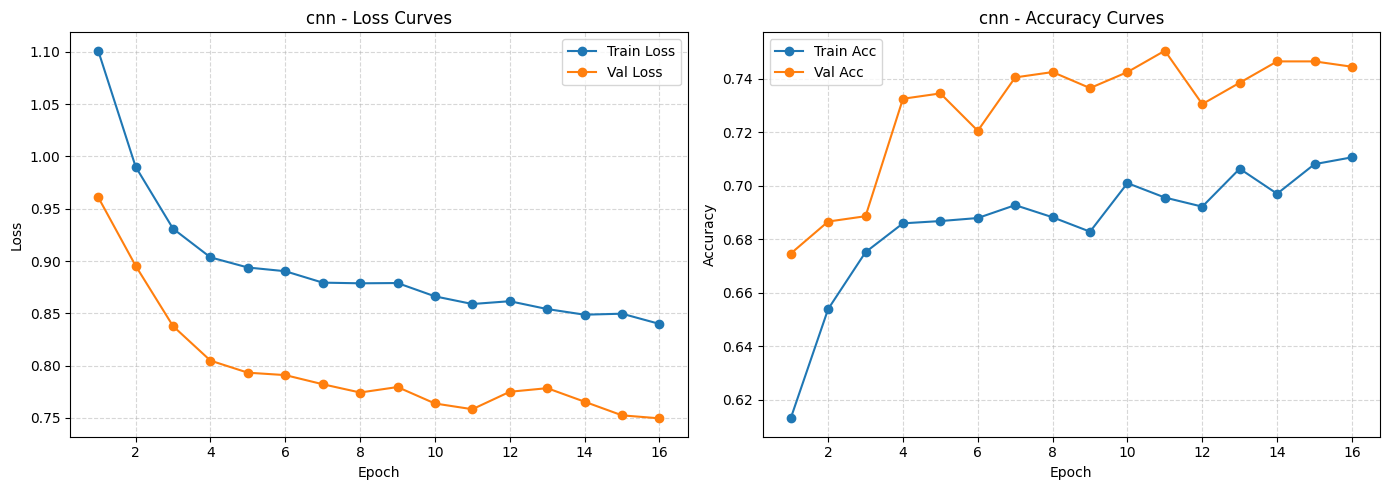

Learning curves saved at: /content/drive/MyDrive/fyp/results/cnn_learning_curves.png


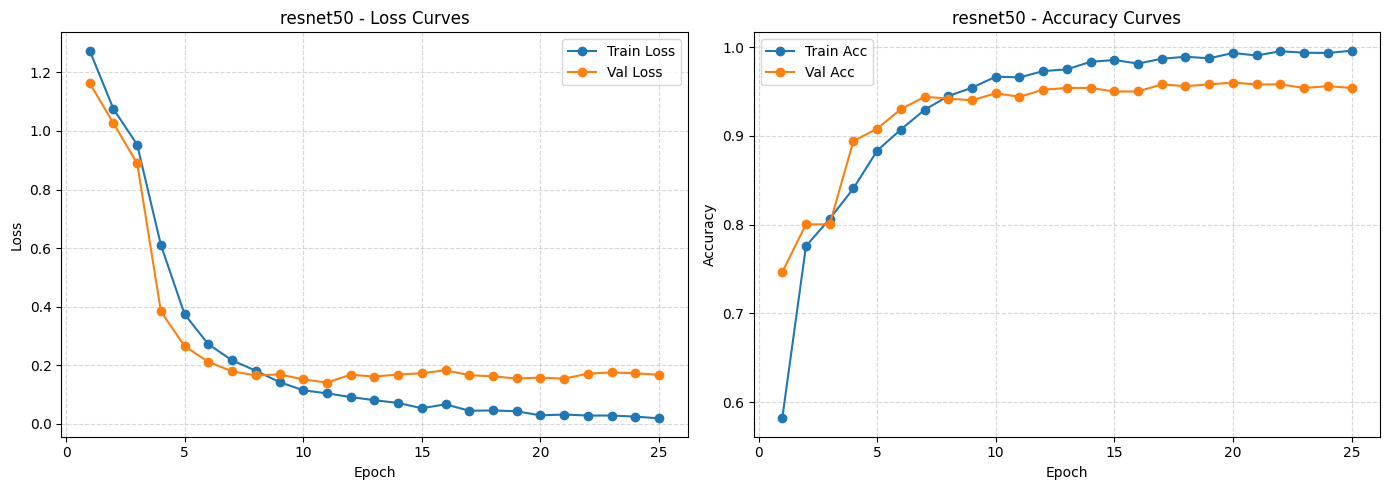

Learning curves saved at: /content/drive/MyDrive/fyp/results/resnet50_learning_curves.png


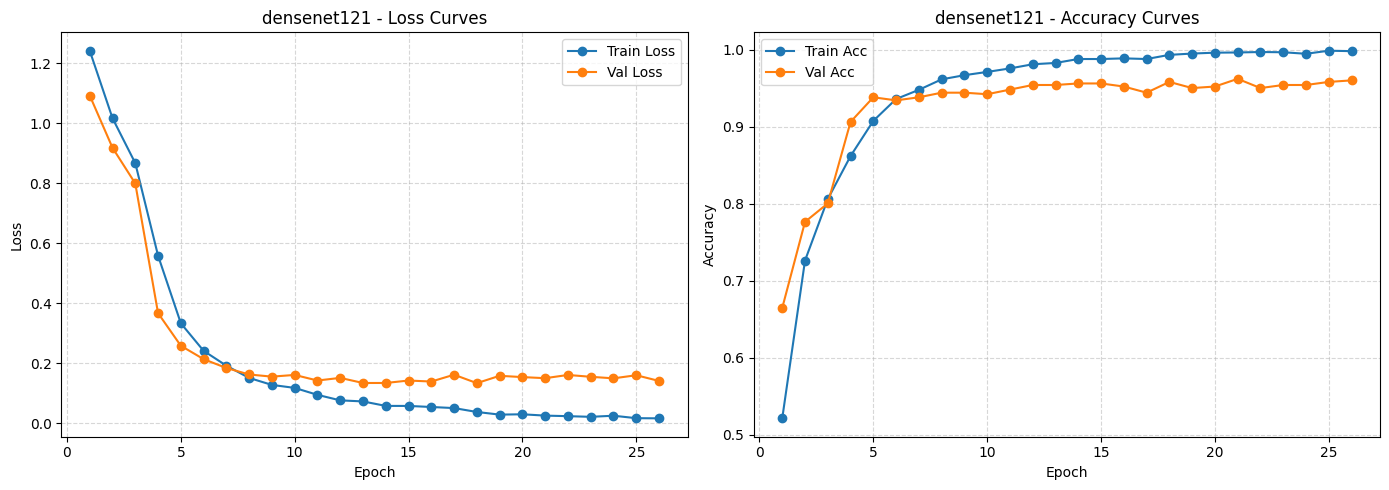

Learning curves saved at: /content/drive/MyDrive/fyp/results/densenet121_learning_curves.png


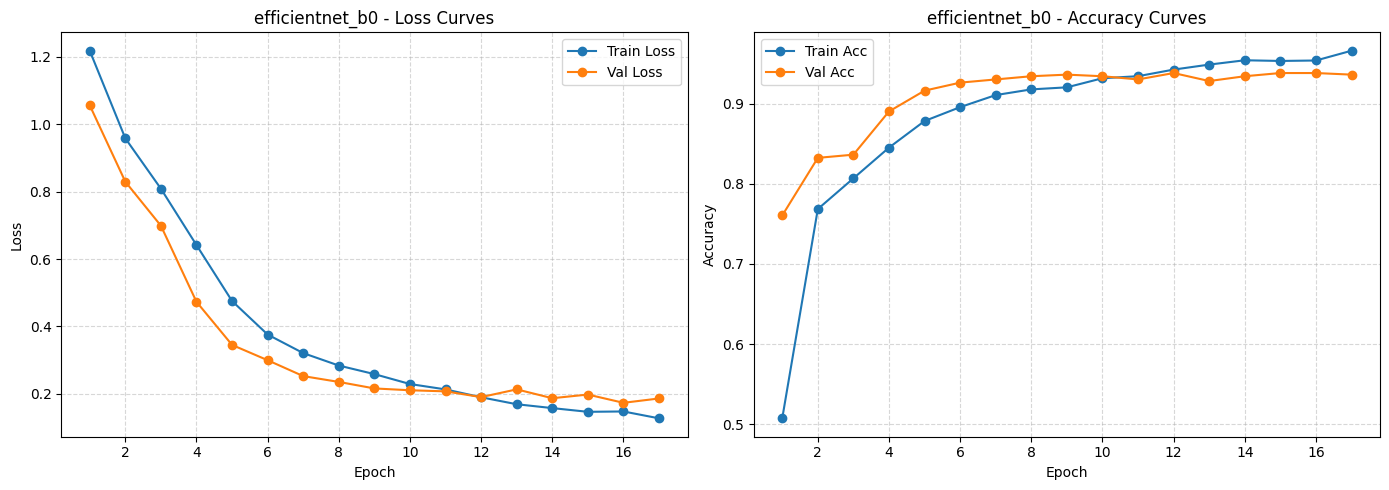

Learning curves saved at: /content/drive/MyDrive/fyp/results/efficientnet_b0_learning_curves.png


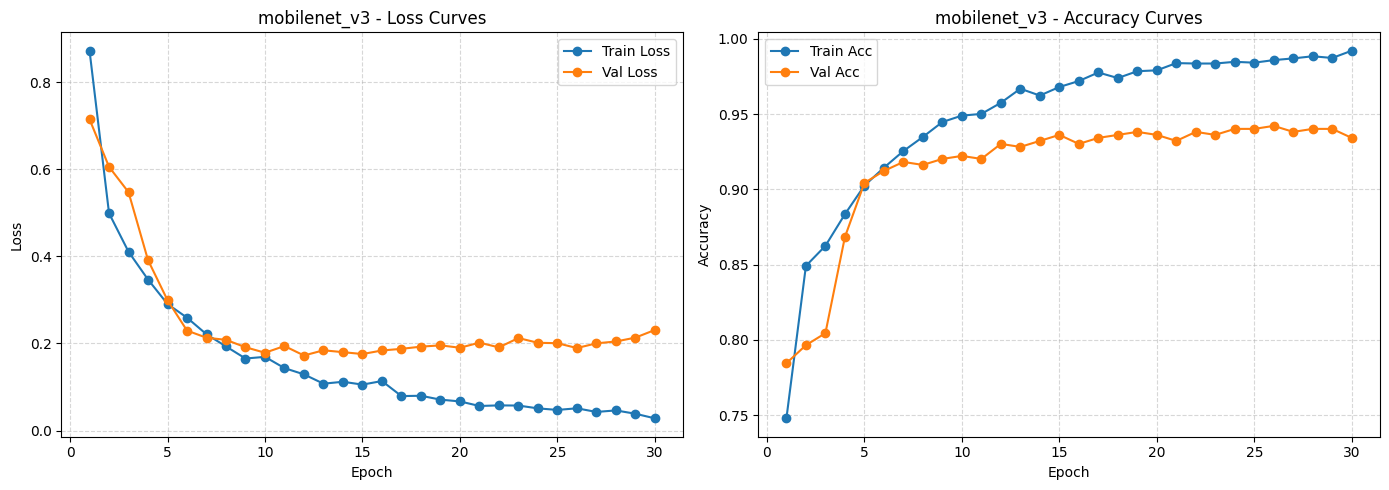

Learning curves saved at: /content/drive/MyDrive/fyp/results/mobilenet_v3_learning_curves.png

--- Starting Comprehensive Test Set Evaluations with Verified Classes ---



Inference on cnn: 100%|██████████| 15/15 [00:03<00:00,  4.60it/s]


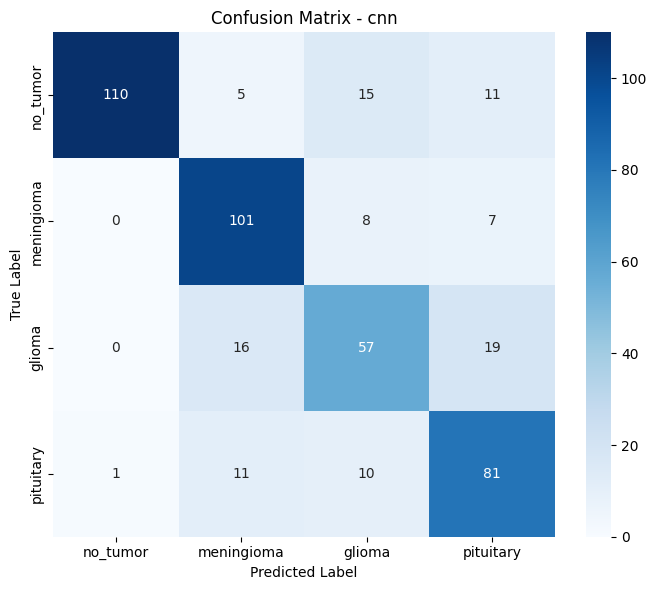

Confusion matrix saved at: /content/drive/MyDrive/fyp/results/cnn_confusion_matrix.png

Classification Report for cnn:

              precision    recall  f1-score   support

    no_tumor       0.99      0.78      0.87       141
  meningioma       0.76      0.87      0.81       116
      glioma       0.63      0.62      0.63        92
   pituitary       0.69      0.79      0.73       103

    accuracy                           0.77       452
   macro avg       0.77      0.76      0.76       452
weighted avg       0.79      0.77      0.78       452

Classification report saved at: /content/drive/MyDrive/fyp/results/cnn_classification_report.txt
--------------------------------------------------


Inference on resnet50: 100%|██████████| 15/15 [00:04<00:00,  3.33it/s]


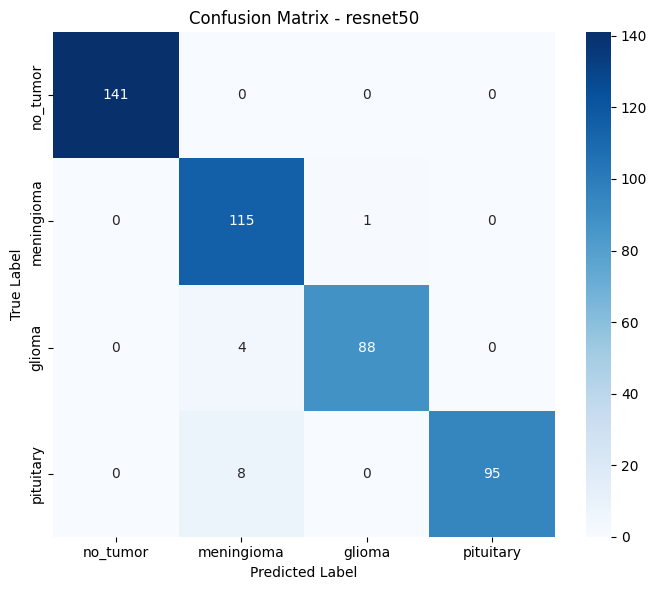

Confusion matrix saved at: /content/drive/MyDrive/fyp/results/resnet50_confusion_matrix.png

Classification Report for resnet50:

              precision    recall  f1-score   support

    no_tumor       1.00      1.00      1.00       141
  meningioma       0.91      0.99      0.95       116
      glioma       0.99      0.96      0.97        92
   pituitary       1.00      0.92      0.96       103

    accuracy                           0.97       452
   macro avg       0.97      0.97      0.97       452
weighted avg       0.97      0.97      0.97       452

Classification report saved at: /content/drive/MyDrive/fyp/results/resnet50_classification_report.txt
--------------------------------------------------


Inference on densenet121: 100%|██████████| 15/15 [00:04<00:00,  3.32it/s]


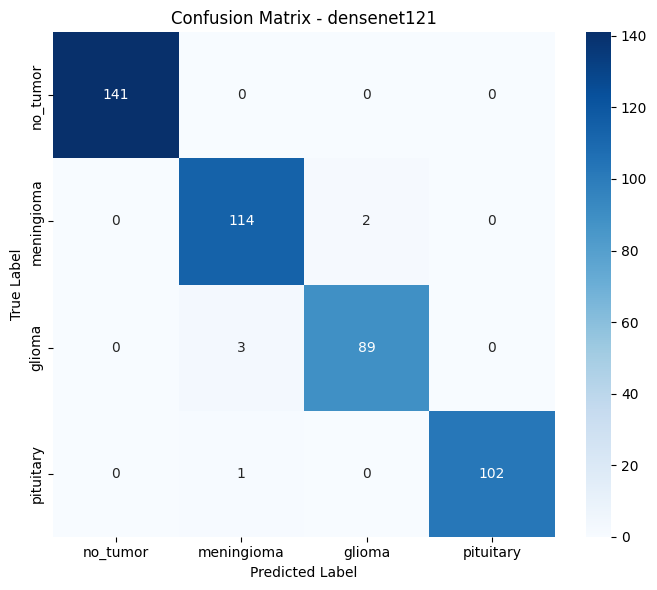

Confusion matrix saved at: /content/drive/MyDrive/fyp/results/densenet121_confusion_matrix.png

Classification Report for densenet121:

              precision    recall  f1-score   support

    no_tumor       1.00      1.00      1.00       141
  meningioma       0.97      0.98      0.97       116
      glioma       0.98      0.97      0.97        92
   pituitary       1.00      0.99      1.00       103

    accuracy                           0.99       452
   macro avg       0.99      0.99      0.99       452
weighted avg       0.99      0.99      0.99       452

Classification report saved at: /content/drive/MyDrive/fyp/results/densenet121_classification_report.txt
--------------------------------------------------


Inference on efficientnet_b0: 100%|██████████| 15/15 [00:03<00:00,  4.18it/s]


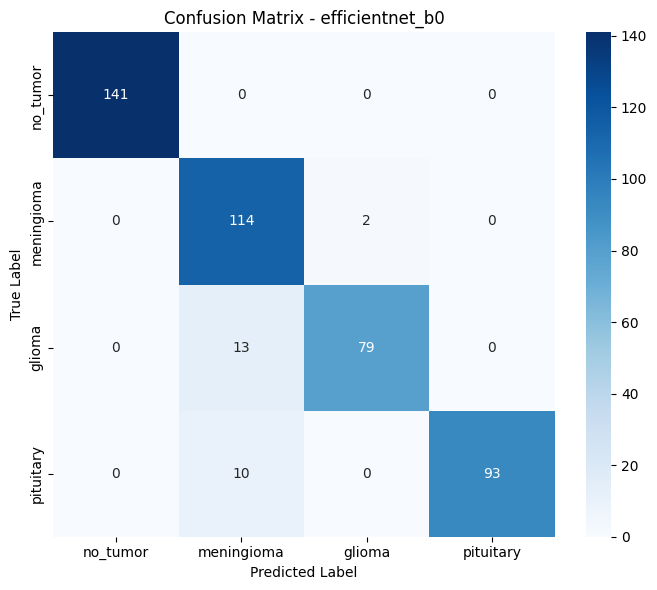

Confusion matrix saved at: /content/drive/MyDrive/fyp/results/efficientnet_b0_confusion_matrix.png

Classification Report for efficientnet_b0:

              precision    recall  f1-score   support

    no_tumor       1.00      1.00      1.00       141
  meningioma       0.83      0.98      0.90       116
      glioma       0.98      0.86      0.91        92
   pituitary       1.00      0.90      0.95       103

    accuracy                           0.94       452
   macro avg       0.95      0.94      0.94       452
weighted avg       0.95      0.94      0.95       452

Classification report saved at: /content/drive/MyDrive/fyp/results/efficientnet_b0_classification_report.txt
--------------------------------------------------


Inference on mobilenet_v3: 100%|██████████| 15/15 [00:03<00:00,  4.44it/s]


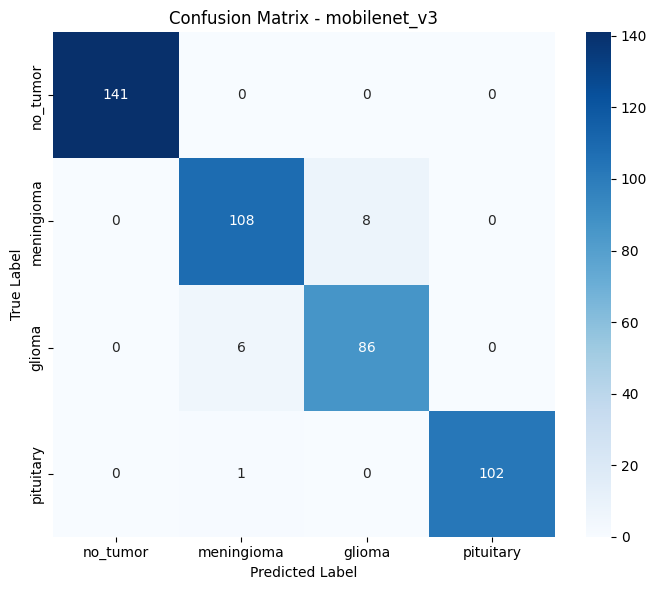

Confusion matrix saved at: /content/drive/MyDrive/fyp/results/mobilenet_v3_confusion_matrix.png

Classification Report for mobilenet_v3:

              precision    recall  f1-score   support

    no_tumor       1.00      1.00      1.00       141
  meningioma       0.94      0.93      0.94       116
      glioma       0.91      0.93      0.92        92
   pituitary       1.00      0.99      1.00       103

    accuracy                           0.97       452
   macro avg       0.96      0.96      0.96       452
weighted avg       0.97      0.97      0.97       452

Classification report saved at: /content/drive/MyDrive/fyp/results/mobilenet_v3_classification_report.txt
--------------------------------------------------


In [69]:
# 1. Plot and save learning curves for all models using their saved CSV histories
history_files = {
    "cnn": RESULT_DIR / "CNN_History.csv",
    "resnet50": RESULT_DIR / "resnet_History.csv",
    "densenet121": RESULT_DIR / "densenet_History.csv",
    "efficientnet_b0": RESULT_DIR / "efficientnet_b0_History.csv",
    "mobilenet_v3": RESULT_DIR / "mobilenet_v3_History.csv"
}

for model_name, path in history_files.items():
    if os.path.exists(path):
        hist_df = pd.read_csv(path)
        plot_and_save_learning_curves(hist_df, model_name)
    else:
        print(f"No training history CSV found for {model_name} at {path}")

print("\n--- Starting Comprehensive Test Set Evaluations with Verified Classes ---\n")

# 2. Generate and save confusion matrices and classification reports using corrected class mapping order
verified_class_names = ['no_tumor', 'meningioma', 'glioma', 'pituitary']
for model_name in ["cnn", "resnet50", "densenet121", "efficientnet_b0", "mobilenet_v3"]:
    evaluate_model_and_save_artifacts(model_name, test_loader, class_names=verified_class_names)

Saving the Configuration Dictionary to Results Folder as well

In [70]:
import json

# Define the output path for the configuration JSON
config_path = RESULT_DIR / "config.json"

# Save the CONFIG dictionary as a formatted JSON file
with open(config_path, 'w') as f:
    json.dump(CONFIG, f, indent=4)

print(f"Configuration dictionary successfully saved to: {config_path}")
# Display the contents to verify
with open(config_path, 'r') as f:
    print(f.read())

Configuration dictionary successfully saved to: /content/drive/MyDrive/fyp/results/config.json
{
    "image_size": 224,
    "batch_size": 32,
    "epochs": 30,
    "lr": 0.0001,
    "num_classes": 4,
    "patience": 5,
    "seed": 42
}
